# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Nathania Dewinta Maharani
- **Email:** thaniamaharani13@gmail.com
- **ID Dicoding:** nathaniadewinta

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari nonkerja selama Januari 2011 hingga Desember 2012, serta pada jam berapa permintaan tertinggi terjadi untuk menentukan waktu penambahan ketersediaan sepeda?
- **Pertanyaan 2:** Seberapa besar perbedaan rata-rata jumlah penyewaan sepeda harian berdasarkan musim dan kondisi cuaca selama Januari 2011 hingga Desember 2012, serta kondisi apa yang memiliki permintaan tertinggi dan terendah untuk mendukung perencanaan operasional penyewaan sepeda?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## Data Wrangling

### Gathering Data

#### Memuat Dataset Bike Sharing

In [2]:
folder_data = Path("data") if Path("data/day.csv").exists() else Path("/content")
day_df = pd.read_csv(folder_data / "day.csv")
hour_df = pd.read_csv(folder_data / "hour.csv")

print("Dataset Harian:")
display(day_df.head())
print("Dataset Per Jam:")
display(hour_df.head())
print("Ukuran dataset harian:", day_df.shape)
print("Ukuran dataset per jam:", hour_df.shape)

Dataset Harian:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Dataset Per Jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Ukuran dataset harian: (731, 16)
Ukuran dataset per jam: (17379, 17)


**Insight:** (Opsional)
- Dataset Bike Sharing punya dua jenis data, yaitu data harian dengan 731 baris dan 16 kolom, serta data per jam dengan 17.379 baris dan 17 kolom.
- Dari kedua dataset ini, kita bisa melihat informasi seperti tanggal, waktu, musim, kondisi cuaca, jenis hari, dan jumlah sepeda yang disewa. Informasi ini nantinya akan digunakan untuk menjawab pertanyaan bisnis yang sudah dibuat.

### Assessing Data

#### Identifying Data Quality Problems

In [3]:
print("Informasi dataset harian:")
day_df.info()
print("\nInformasi dataset per jam:")
hour_df.info()
print("\nMissing value harian:")
print(day_df.isna().sum())
print("\nMissing value per jam:")
print(hour_df.isna().sum())

Informasi dataset harian:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Informasi dataset per jam:
<class 'pandas.core.frame.DataFrame'>
R

In [4]:
print("Duplikat data harian:", day_df.duplicated().sum())
print("Duplikat data per jam:", hour_df.duplicated().sum())

print("Kelembapan nol data harian:",
      (day_df["hum"] == 0).sum())

print("Kelembapan nol data per jam:",
      (hour_df["hum"] == 0).sum())

print("Total tidak sesuai data harian:",
      (day_df["cnt"] != day_df["casual"] + day_df["registered"]).sum())

print("Total tidak sesuai data per jam:",
      (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum())

Duplikat data harian: 0
Duplikat data per jam: 0
Kelembapan nol data harian: 1
Kelembapan nol data per jam: 22
Total tidak sesuai data harian: 0
Total tidak sesuai data per jam: 0


**Steps to Take:**
- Mengubah kolom dteday dari object ke datetime supaya analisis berdasarkan tanggal lebih mudah.
- Mengecek nilai kelembapan hum = 0 yang mencurigakan (1 baris harian dan 22 baris per jam), lalu menanganinya menggunakan median per kelompok bulan/jam sebagai asumsi nilai pengukuran tidak tersedia. Jumlah penyewaan tetap dipertahankan.

**Insight:** (Opsional)
- Kedua dataset tidak punya missing value atau baris duplikat. Total penyewaan cnt juga sudah sesuai dengan penjumlahan casual dan registered.
- Kolom dteday masih bertipe teks (object). Ada juga 1 nilai hum = 0 pada data harian dan 22 pada data per jam yang ditandai sebagai nilai mencurigakan untuk ditangani di tahap cleaning.

### Cleaning Data

#### Fixing Data Type and Humidity Problems

In [5]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

day_df["hum"] = day_df["hum"].replace(0, np.nan)
hour_df["hum"] = hour_df["hum"].replace(0, np.nan)

day_df["hum"] = day_df["hum"].fillna(
    day_df.groupby("mnth")["hum"].transform("median")
)

hour_df["hum"] = hour_df["hum"].fillna(
    hour_df.groupby(["mnth", "hr"])["hum"].transform("median")
)

print("Cleaning Data selesai!")

Cleaning Data selesai!


In [6]:
print("Tipe tanggal harian:", day_df["dteday"].dtype)
print("Tipe tanggal per jam:", hour_df["dteday"].dtype)

print("Missing value harian:", day_df.isna().sum().sum())
print("Missing value per jam:", hour_df.isna().sum().sum())

print("Kelembapan nol harian:", (day_df["hum"] == 0).sum())
print("Kelembapan nol per jam:", (hour_df["hum"] == 0).sum())

print("Jumlah baris harian:", len(day_df))
print("Jumlah baris per jam:", len(hour_df))

Tipe tanggal harian: datetime64[ns]
Tipe tanggal per jam: datetime64[ns]
Missing value harian: 0
Missing value per jam: 0
Kelembapan nol harian: 0
Kelembapan nol per jam: 0
Jumlah baris harian: 731
Jumlah baris per jam: 17379


**Insight:** (Opsional)
- Kolom dteday pada kedua dataset sudah berhasil diubah menjadi datetime, jadi sekarang data tanggal lebih mudah digunakan untuk analisis.
- Nilai kelembapan 0 yang mencurigakan sudah ditangani menggunakan median. Jumlah baris pada kedua dataset juga tetap sama, sehingga data penyewaan tidak ada yang terhapus.

## Exploratory Data Analysis (EDA)

####Pertanyaan 1 — Pola Penyewaan per Jam pada Hari Kerja dan Nonkerja

In [7]:
penyewaan_per_jam = hour_df.groupby(
    ["workingday", "hr"]
)["cnt"].mean().reset_index()

penyewaan_per_jam["jenis_hari"] = penyewaan_per_jam[
    "workingday"
].map({
    0: "Hari Nonkerja",
    1: "Hari Kerja"
})

penyewaan_per_jam.rename(
    columns={
        "hr": "jam",
        "cnt": "rata_rata_penyewaan"
    },
    inplace=True
)

display(penyewaan_per_jam.head(10))

,workingday,jam,rata_rata_penyewaan,jenis_hari
0,0,0,90.800000,Hari Nonkerja
1,0,1,69.508696,Hari Nonkerja
2,0,2,53.171053,Hari Nonkerja
3,0,3,25.775330,Hari Nonkerja
4,0,4,8.264317,Hari Nonkerja
5,0,5,8.689189,Hari Nonkerja
6,0,6,18.742358,Hari Nonkerja
7,0,7,43.406926,Hari Nonkerja
8,0,8,105.653680,Hari Nonkerja
9,0,9,171.623377,Hari Nonkerja


In [8]:
jam_tertinggi = penyewaan_per_jam.loc[
    penyewaan_per_jam.groupby("jenis_hari")[
        "rata_rata_penyewaan"
    ].idxmax()
]

print("Jam dengan rata-rata penyewaan tertinggi:")
display(jam_tertinggi[
    ["jenis_hari", "jam", "rata_rata_penyewaan"]
].round(2))

selisih = (
    jam_tertinggi["rata_rata_penyewaan"].max()
    - jam_tertinggi["rata_rata_penyewaan"].min()
)

print(f"Selisih rata-rata penyewaan tertinggi: {selisih:.2f}")

Jam dengan rata-rata penyewaan tertinggi:


,jenis_hari,jam,rata_rata_penyewaan
41,Hari Kerja,17,525.29
13,Hari Nonkerja,13,372.73


Selisih rata-rata penyewaan tertinggi: 152.56


**Insight:** (Opsional)
- Pada hari kerja, rata-rata penyewaan sepeda paling tinggi terjadi pukul 17.00, yaitu sekitar 525 sepeda. Sementara itu, pada hari nonkerja, penyewaan paling ramai terjadi pukul 13.00 dengan rata-rata sekitar 373 sepeda.
- Selisih rata-rata penyewaan pada kedua jam tersibuk tersebut sekitar 153 sepeda. Dari sini terlihat kalau pola penyewaan antara hari kerja dan hari nonkerja berbeda, sehingga ketersediaan sepeda perlu disesuaikan dengan waktu yang paling ramai.

#### Pertanyaan 2 — Pola Penyewaan Harian menurut Musim dan Cuaca

In [9]:
day_df["nama_musim"] = day_df["season"].map({
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
})

day_df["kondisi_cuaca"] = day_df["weathersit"].map({
    1: "Cerah",
    2: "Berkabut/Berawan",
    3: "Hujan/Salju Ringan",
    4: "Cuaca Buruk"
})

penyewaan_musim = (
    day_df.groupby("nama_musim")["cnt"]
    .mean()
    .sort_values(ascending=False)
)

print("Rata-rata penyewaan berdasarkan musim:")
display(penyewaan_musim.round(2))

penyewaan_cuaca = (
    day_df.groupby("kondisi_cuaca")["cnt"]
    .mean()
    .sort_values(ascending=False)
)

print("Rata-rata penyewaan berdasarkan cuaca:")
display(penyewaan_cuaca.round(2))

print("Selisih berdasarkan musim:",
      round(penyewaan_musim.max() - penyewaan_musim.min(), 2))

print("Selisih berdasarkan cuaca:",
      round(penyewaan_cuaca.max() - penyewaan_cuaca.min(), 2))

Rata-rata penyewaan berdasarkan musim:


,cnt
nama_musim,
Fall,5644.30
Summer,4992.33
Winter,4728.16
Spring,2604.13


Rata-rata penyewaan berdasarkan cuaca:


,cnt
kondisi_cuaca,
Cerah,4876.79
Berkabut/Berawan,4035.86
Hujan/Salju Ringan,1803.29


Selisih berdasarkan musim: 3040.17
Selisih berdasarkan cuaca: 3073.5


**Insight EDA Pertanyaan 2:**
- Penyewaan harian paling tinggi terjadi pada musim Fall (rata-rata 5.644,30), sedangkan Spring terendah (2.604,13). Selisih rata-ratanya 3.040,17 penyewaan per hari.
- Saat cuaca cerah, rata-rata penyewaan 4.876,79 per hari. Saat hujan/salju ringan, rata-ratanya 1.803,29. Selisihnya 3.073,50 per hari. Ini menunjukkan perbedaan pola permintaan, bukan bukti bahwa cuaca menjadi satu-satunya penyebab.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Perbandingan Rata-rata Penyewaan Sepeda per Jam pada Hari Kerja dan Hari Nonkerja (Januari 2011–Desember 2012)

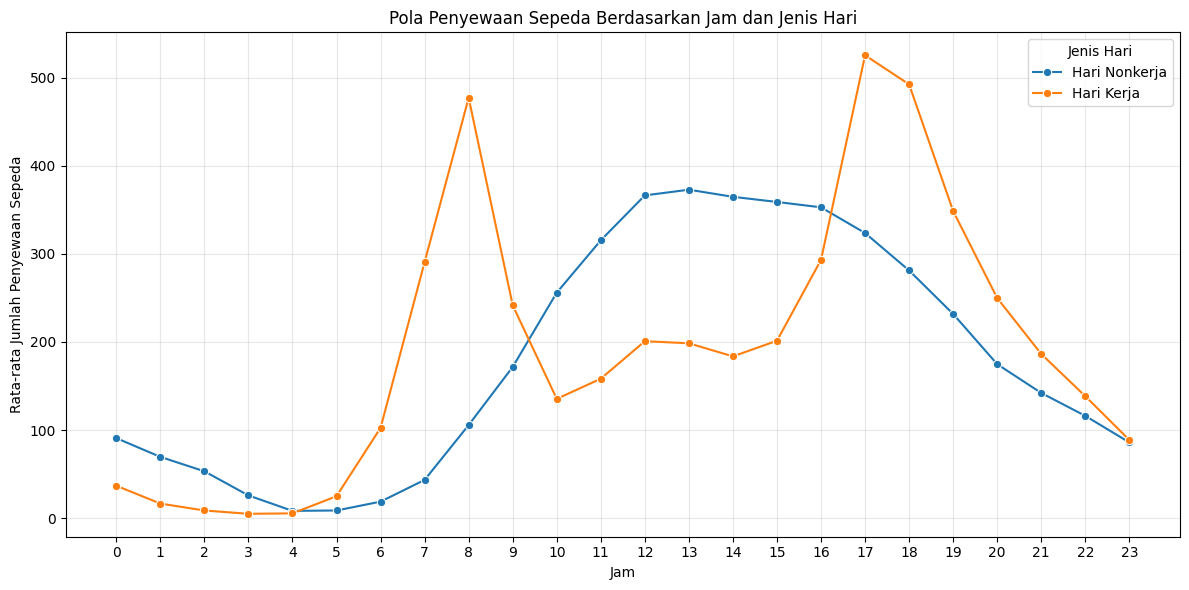

In [10]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=penyewaan_per_jam,
    x="jam",
    y="rata_rata_penyewaan",
    hue="jenis_hari",
    marker="o"
)

plt.title("Pola Penyewaan Sepeda Berdasarkan Jam dan Jenis Hari")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Jumlah Penyewaan Sepeda")
plt.xticks(range(0, 24))
plt.legend(title="Jenis Hari")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

**Insight Visualisasi Pertanyaan 1:**
- Pada hari kerja, jam tersibuk pukul 17.00 dengan rata-rata 525,29 penyewaan per jam. Ada juga lonjakan pada pukul 08.00.
- Pada hari nonkerja, puncaknya pukul 13.00 dengan rata-rata 372,73 penyewaan per jam. Jam puncak hari kerja lebih tinggi 152,56 daripada jam puncak nonkerja. Polanya bisa jadi pertimbangan penyesuaian ketersediaan sepeda.

### Pertanyaan 2: Perbandingan Rata-rata Penyewaan Sepeda Harian Berdasarkan Musim dan Kondisi Cuaca (Januari 2011–Desember 2012)

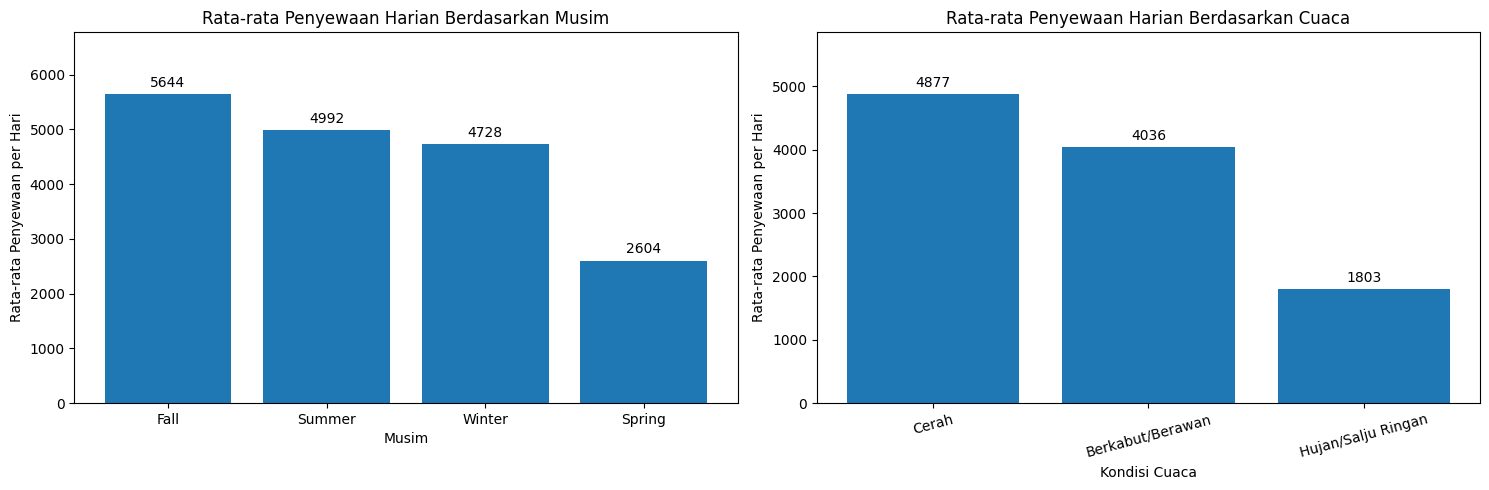

In [11]:
musim_plot = penyewaan_musim.reset_index()
cuaca_plot = penyewaan_cuaca.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

batang_musim = axes[0].bar(musim_plot["nama_musim"], musim_plot["cnt"])
axes[0].set_title("Rata-rata Penyewaan Harian Berdasarkan Musim")
axes[0].set_xlabel("Musim")
axes[0].set_ylabel("Rata-rata Penyewaan per Hari")
axes[0].set_ylim(bottom=0, top=musim_plot["cnt"].max() * 1.2)
axes[0].bar_label(batang_musim, fmt="%.0f", padding=3)

batang_cuaca = axes[1].bar(cuaca_plot["kondisi_cuaca"], cuaca_plot["cnt"])
axes[1].set_title("Rata-rata Penyewaan Harian Berdasarkan Cuaca")
axes[1].set_xlabel("Kondisi Cuaca")
axes[1].set_ylabel("Rata-rata Penyewaan per Hari")
axes[1].set_ylim(bottom=0, top=cuaca_plot["cnt"].max() * 1.2)
axes[1].bar_label(batang_cuaca, fmt="%.0f", padding=3)
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

**Insight Visualisasi Pertanyaan 2:**
- Rata-rata penyewaan harian tertinggi terjadi pada Fall (5.644,30) dan terendah pada Spring (2.604,13). Perbedaannya sekitar 3.040 penyewaan per hari.
- Saat cuaca cerah rata-ratanya 4.876,79 penyewaan per hari, sementara saat hujan/salju ringan rata-ratanya 1.803,29. Selisihnya 3.073,50. Pengelola bisa memakai pola ini untuk merencanakan kapasitas operasional.

## Analisis Lanjutan (Opsional)

Analisis lanjutan ini menggunakan teknik *binning* untuk membagi waktu penyewaan menjadi lima kelompok, yaitu dini hari, pagi, siang, sore, dan malam. Tujuannya supaya kita lebih mudah melihat pola penyewaan pada setiap kelompok waktu, baik di hari kerja maupun hari nonkerja.

In [12]:
label_periode = ["Dini hari (00-05)", "Pagi (06-10)", "Siang (11-15)", "Sore (16-19)", "Malam (20-23)"]
hour_df["periode_hari"] = pd.cut(
    hour_df["hr"], bins=[-1, 5, 10, 15, 19, 23],
    labels=label_periode, include_lowest=True
)

rangkuman_periode = hour_df.groupby(["workingday", "periode_hari"], observed=True)["cnt"].mean().reset_index()
rangkuman_periode["jenis_hari"] = rangkuman_periode["workingday"].map({0: "Hari Nonkerja", 1: "Hari Kerja"})
print("Rata-rata penyewaan per jam pada tiap kelompok waktu:")
display(rangkuman_periode[["jenis_hari", "periode_hari", "cnt"]].round(2))

Rata-rata penyewaan per jam pada tiap kelompok waktu:


,jenis_hari,periode_hari,cnt
0,Hari Nonkerja,Dini hari (00-05),43.00
1,Hari Nonkerja,Pagi (06-10),119.24
2,Hari Nonkerja,Siang (11-15),355.55
3,Hari Nonkerja,Sore (16-19),297.34
4,Hari Nonkerja,Malam (20-23),129.70
5,Hari Kerja,Dini hari (00-05),16.44
6,Hari Kerja,Pagi (06-10),249.40
7,Hari Kerja,Siang (11-15),188.50
8,Hari Kerja,Sore (16-19),414.75
9,Hari Kerja,Malam (20-23),165.78


**Insight:** (Opsional)
- Pengelompokan jam menjadi dini hari, pagi, siang, sore, dan malam membantu merangkum periode operasional yang perlu dipantau. Hasilnya dapat dipakai sebagai pemeriksaan tambahan untuk rencana penempatan sepeda pada hari kerja dan nonkerja.
- Kategori dibuat menggunakan batas waktu yang mudah diinterpretasikan, bukan algoritma clustering machine learning.

## Menyimpan Data untuk Dashboard

In [13]:
folder_dashboard = Path("dashboard")
folder_dashboard.mkdir(exist_ok=True)

df_per_jam = hour_df.copy()
df_per_jam.to_csv(folder_dashboard / "main_data.csv", index=False)

df_harian = day_df.copy()
df_harian.to_csv(folder_dashboard / "day_data.csv", index=False)

print("File data dashboard berhasil disimpan di:", folder_dashboard.resolve())

File data dashboard berhasil disimpan di: /content/dashboard


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Selama Januari 2011–Desember 2012, jam tersibuk pada hari kerja adalah pukul 17.00 (rata-rata 525,29 penyewaan per jam), sedangkan hari nonkerja pada pukul 13.00 (372,73 penyewaan per jam). Selisih pada kedua jam puncak mencapai 152,56 penyewaan per jam. Hal ini menunjukkan perbedaan pola permintaan berdasarkan jenis hari.
- **Conclusion pertanyaan 2:** Musim Fall memiliki rata-rata penyewaan harian tertinggi (5.644,30), sedangkan Spring terendah (2.604,13), dengan selisih 3.040,17. Berdasarkan cuaca, kondisi cerah tertinggi (4.876,79) dan hujan/salju ringan terendah (1.803,29), dengan selisih 3.073,50 penyewaan harian.


**Rekomendasi Action Item:**
- Pengelola sebaiknya mengecek dan menambah ketersediaan sepeda sebelum jam sibuk hari kerja (terutama sekitar pukul 08.00 dan 17.00) serta menjelang siang pada hari nonkerja (sekitar pukul 13.00).
- Gunakan informasi musim dan perkiraan cuaca untuk merencanakan stok, penugasan petugas, dan pemeliharaan sepeda. Saat permintaan diperkirakan lebih rendah, jadwalkan lebih banyak aktivitas perawatan. Rekomendasi ini perlu diuji dengan data operasional terbaru sebelum diterapkan.